# Regresion Lineal

Lo que queremos hacer es crear nuetros datos de trabajo (30 empleados, donde `x` son sus **años de experiencia** e `y` es su **salario anual en miles de euros**), los guardamos en un archivo CSV y dibujaros en un gráfico de dispersión **(Scatter Plot)**

Si descargamos un dataset desconocido de internet, no sabemos que formula real hay detras. 

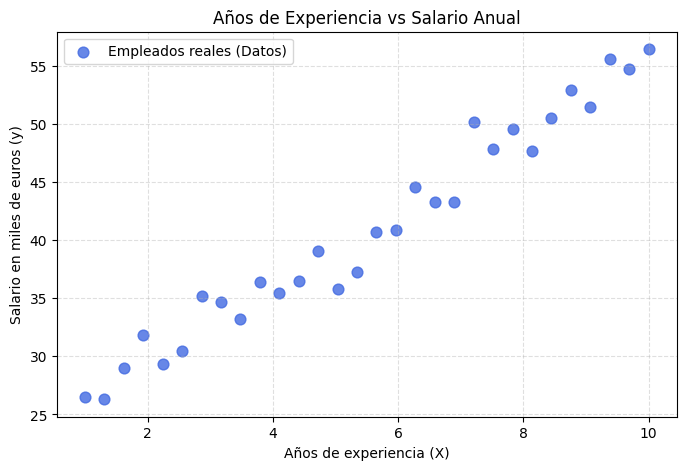

,experiencia_anios,salario_miles_eur
0,1.00,26.49
1,1.31,26.31
2,1.62,28.97
3,1.93,31.80
4,2.24,29.38


In [6]:
import os
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

#Fijamos semillas aleatorias para que los 30 puntos salgan siempre iguales
np.random.seed(42)

#Creamos X: 30 empleados con experiencia repartida entre 1 y 10 años
#Creamos una lista de 30 números espaciados a la misma distancia empezando en 1 año
# en 1 años ( 1.0, 1.31, 1.62 ..)
X = np.linspace(1, 10, 30)

#Creamos y: Salario (miles de euros) = 3.5 * X + 22 + variación aleatoria (ruido)
#Genera 30 números al azar alrededor de 0 (unos positivos y otros negativos, con una desviación media de 2.0 que simulan 
# las diferencias naturales de sueldo entre empleados
ruido = np.random.normal(0, 2.0, size=30)
y = 3.5 * X + 22.0 + ruido

#Guardamos esta tabla dentro de un CSV dentro de data/
df = pd.DataFrame({
    "experiencia_anios": X.round(2),
    "salario_miles_eur": y.round(2)
})

df.to_csv("../data/salarios.csv", index=False)

#Dibujamos la nube de puntos (Scatter Plot)
plt.figure(figsize=(8,5))
plt.scatter(X, y, color="royalblue", s=60, alpha=0.8, label="Empleados reales (Datos)")
plt.title("Años de Experiencia vs Salario Anual")
plt.xlabel("Años de experiencia (X)")
plt.ylabel("Salario en miles de euros (y)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

#Guardamos gráfico y mostramos los primeros 5 empleados de la tabla
plt.savefig("../reports/figures/01_scatter_datos.png", dpi=150, bbox_inches="tight")
plt.show()

df.head()

## Funciones Matematicas

`predecir(X, w, b)`: Dibuja una línea recta con cualquier inclunación (w) y una altura incial(b) que le digamos

`calcular_mse(y_real, y_pred)`: Nuestro "termómetro de error", que mide con un solo número qué tan lejos está esa línea recta de los 30 puntos azules reales

### Explicación de porque necesitamos este medidor de erorr (MSE)

Cuando nuestro algoritmo empieza a aprender, **no sabes cuánto valen `w` ni `b`, así que empieza probando a ciegas con `w = 0`y `b = 0`(prediciendo que los 30 empleados cobran 0 euros)

1. Mira la distancia vertical entre cada punto azul real (y) y la línea recta (y_pred): 
    - diferencia = y - y^

2. La eleva al cuadrado (** 2):

    Para que al restarse no de 0 de error y tambien porque al elevar al cuadrado castigas muchísimo más los fallos grandes.

3. Hace la media de los 3 empleados (`np.mean`)

    - MSE gigante -> la recta está lejísimos de los puntos
    - MSE pequeñito (cerca de 0) -> la recta pasa justo por el centro de los puntos

Recta inicial a ciegas -> w = 0.0, b =0.0
Error inicial (MSE):  1750.74 (Gigante porque la recta está en el suelo)


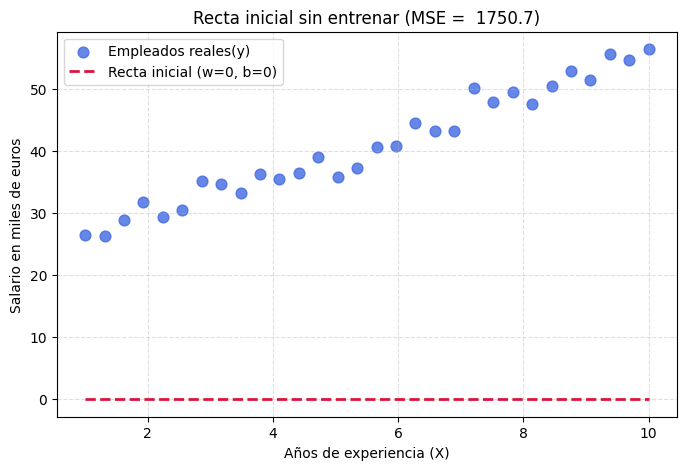

In [8]:
#Funcion de la recta: calcula el salario estimado (y_pred = w * X + b)
def predecir(X, w, b):

    #Formula de la regresion lineal, con el peso, el valor y el valor inicial
    return w * X  + b 

#Función de Error Cuadrático Medio(MSE): mide qué tan lejos está la recta de los puntos
def calcular_mse(y_real, y_pred):
    errores = y_real - y_pred
    return np.mean(errores ** 2)

#Probamos cómo empieza la máquina antes de entrenar (a ciegas: w = 0, b = 0)
w_inicial = 0.0
b_inicial = 0.0

y_pred_inicial = predecir(X, w_inicial, b_inicial)
error_inicial = calcular_mse(y, y_pred_inicial)

print(f"Recta inicial a ciegas -> w = {w_inicial}, b ={b_inicial}")
print(f"Error inicial (MSE): {error_inicial: .2f} (Gigante porque la recta está en el suelo)")

#Dibujamos cómo se ve esa recta en el suelo frente a los puntos reales
plt.figure(figsize=(8,5))
plt.scatter(X, y, color= "royalblue", s = 60, alpha=0.8, label="Empleados reales(y)")
plt.plot(X, y_pred_inicial, color="crimson", linewidth=2, linestyle="--", label="Recta inicial (w=0, b=0)")
plt.title(f"Recta inicial sin entrenar (MSE = {error_inicial: .1f})" )
plt.xlabel("Años de experiencia (X)")
plt.ylabel("Salario en miles de euros")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.show()

## Descenso de Gradiente

La idea es justamente que esa línea roja suba y se incline ella sola hasta colocarse encima de los puntos azules y bajar el error de 1750 a casi 3.

Para que la máquina aprende sola , hace un bucle `for` repitiendo siempre 3 cosas:

1. Calcular las derivadas **(dw y db)**

    - db: Altura
        `db = -2 *np.mean(X * (y - y_pred))`
        Mira cuánto nos falta girar la pendiente de la rect (multiplicando el error por los años X)
    
    -dw: Inclinación
        `dw = -2 * np.mean(X * (y - y_pred))`
        Mira cuánto nos falta girar la pendiente de la recta (multiplicando el error por los años X)

2. El tamaño del paso: `learning_rate` (Tasa de aprendizaje = `0.01` )

No podemos mover la recta de un salto gigante de golpe, porque nos pasaríamos de largo y el error rebotaría sin control. Por eso multiplicamos por un número pequeñito ( `learning_rate = 0.01` ) para acercarnos dando pasitos suaves y seguros

3. Las repeticiones: `epochs` (Épocas = `3000` intentos)

Como damos pasitos pequeños, metemos la actualización dentro de un bucle de `3000` vueltas (`epochs`):

In [10]:
def entrenar_descenso_gradiente(X, y, learning_rate=0.01, epochs=3000):
    #Empezamos a ciegas
    w = 0.0
    b = 0.0

    #Guardaremos el error de cada vuelta para dibujarlo en la proxima fase
    historial_mse = []

    #Bucle de aprendizaje (damos 3000 pasitos)
    for epoca in range(epochs):
        #Precedimos con la recta actual
        y_pred = predecir(X, w, b)

        #Medir el error actual y guardarlo
        mse = calcular_mse(y, y_pred)
        historial_mse.append(mse)

        #Calculamos la brújula (derivadas dw y db)
        dw = -2 * np.mean(X *(y - y_pred))
        db = -2 * np.mean(y - y_pred)

        #Dar un pasito para mejorar w y b
        w = w - learning_rate * dw
        b = b - learning_rate * db

        #Imprimimos el progreso cada 500 épocas para ver cómo aprende en vivo
        if epoca % 500 == 0:
            print(f"Época {epoca:4d} | MSE: {mse: 8.2f} | w: {w: .2f} | b: {b: .2f}")
    
    return w, b, historial_mse

#Ejecutamos el entrenamiento de nuestra máquina
w_final, b_final, historial_mse = entrenar_descenso_gradiente(X, y, learning_rate=0.01, epochs=3000)

print("-" * 55)
print(f"Entranmiento terminado")
print(f"Fórmula real secreta -> Subida (w) = 3.50 | Base (b) = 22.00")
print(f"Descubierto por NumPy -> Subida (w) = { w_final: .2f} | Base (b) = {b_final: .2f}")
print(f"Error final (MSE): {historial_mse[-1]: .2f} (bajó desde 1750.74)")

Época    0 | MSE:  1750.74 | w:  4.97 | b:  0.82
Época  500 | MSE:     4.88 | w:  3.76 | b:  19.57
Época 1000 | MSE:     2.81 | w:  3.35 | b:  22.37
Época 1500 | MSE:     2.76 | w:  3.28 | b:  22.79
Época 2000 | MSE:     2.76 | w:  3.28 | b:  22.86
Época 2500 | MSE:     2.76 | w:  3.27 | b:  22.87
-------------------------------------------------------
Entranmiento terminado
Fórmula real secreta -> Subida (w) = 3.50 | Base (b) = 22.00
Descubierto por NumPy -> Subida (w) =  3.27 | Base (b) =  22.87
Error final (MSE):  2.76 (bajó desde 1750.74)
